# BTL XỬ LÝ ẢNH — HISTOGRAM AND HISTOGRAM EQUALIZATION

**Nhóm thực hiện:** Nhóm 5    



**Thông tin nhóm:**

| STT | Họ và tên | MSSV |
|:--:|---|---|
| 1 | Trần Vĩnh Huy | 2311256 |
| 2 | Phạm Hoàng Đăng | 2310732 |
| 3 | Đàm Lê Khải | 2311545 |


In [5]:
# Khai báo thư viện và kiểm tra môi trường
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display

from src.preprocessing import convert_to_grayscale, convert_to_8bit
from src.histogram import calculate_histogram, normalize_histogram, calculate_cdf
from src.equalization import manual_equalization, opencv_equalization
from src.adaptive_equalization import manual_ahe, opencv_clahe
from src.histogram_matching import (
    manual_histogram_matching,
    skimage_histogram_matching,
    convert_matching_to_8bit,
    calculate_histogram_distance,
)
from src.metrics import calculate_metrics, calculate_exact_match
from src.visualization import display_results, display_cdf_comparison

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": False})
print("Python:", sys.version.split()[0])

Python: 3.13.14


## 1. Lý thuyết cơ sở — Histogram, PDF và CDF

Cho ảnh xám 8-bit $I(x,y)$, các mức cường độ $k\in\{0,1,\dots,255\}$:

- **Histogram:** $h(k)$ là số pixel có mức xám bằng $k$.
- **PDF (histogram chuẩn hóa):** $p(k)=\dfrac{h(k)}{MN}$, với $M\times N$ là số pixel của ảnh. Do đó $\sum_{k=0}^{255}p(k)=1$.
- **CDF (phân phối tích lũy):** $F(k)=\sum_{i=0}^{k}p(i)$; $F(k)$ không giảm và $F(255)=1$.

**Ý nghĩa:** histogram cho biết phân bố sáng/tối; PDF mô tả xác suất mức xám; CDF dùng để xây dựng phép ánh xạ mức xám trong Equalization và Matching.

### 1.1. Chuẩn bị ảnh thử nghiệm


In [6]:
IMAGE_PATHS = {
    "source": Path("images/lena.jpg"),
    "low": Path("images/low-exposure.jpg"),
    "high": Path("images/high-exposure.jpg"),
    "target": Path("images/lena.jpg"),
}

rng = np.random.default_rng(2026)

y, x = np.mgrid[0:192, 0:256]
base = 85 + 65 * (x / 255) + 38 * np.sin(x / 22) * np.cos(y / 27)
base += 28 * (((x - 130) ** 2 + (y - 96) ** 2) < 48 ** 2)
base += rng.normal(0, 5, base.shape)
base = np.clip(np.rint(base), 0, 255).astype(np.uint8)

demo_low = np.clip(np.rint(base.astype(float) * 0.48), 0, 255).astype(np.uint8)
demo_high = np.clip(np.rint(base.astype(float) * 1.27 + 20), 0, 255).astype(np.uint8)
demo_target = np.clip(
    np.rint(190 - cv2.resize(base, (224, 160)).astype(float) * 0.62 + rng.normal(0, 3, (160, 224))),
    0, 255
).astype(np.uint8)


def load_gray_or_fallback(path, fallback):
    if path.is_file():
        raw = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
        if raw is None:
            print(f"Không đọc được {path}; dùng ảnh khác.")
        else:
            image = convert_to_8bit(convert_to_grayscale(raw))
            print(f"Đã tải {path}: {image.shape}, {image.dtype}")
            return image
    return fallback.copy()

source_image = load_gray_or_fallback(IMAGE_PATHS["source"], base)
low_image = load_gray_or_fallback(IMAGE_PATHS["low"], demo_low)
high_image = load_gray_or_fallback(IMAGE_PATHS["high"], demo_high)
target_image = load_gray_or_fallback(IMAGE_PATHS["target"], demo_target)

assert all(im.ndim == 2 and im.dtype == np.uint8 for im in
           (source_image, low_image, high_image, target_image))

Đã tải images\lena.jpg: (512, 512), uint8
Đã tải images\low-exposure.jpg: (1024, 1538), uint8
Đã tải images\high-exposure.jpg: (1024, 1538), uint8
Đã tải images\lena.jpg: (512, 512), uint8


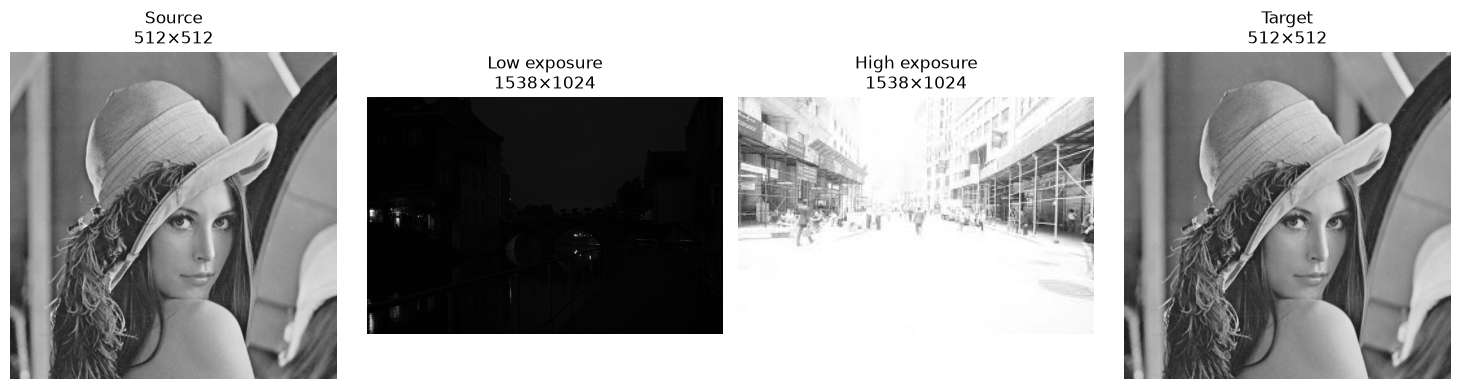

In [7]:
# Hiển thị các ảnh đầu vào và thông tin kích thước.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (name, image) in zip(axes, [
    ("Source", source_image), ("Low exposure", low_image),
    ("High exposure", high_image), ("Target", target_image)
]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name}\n{image.shape[1]}×{image.shape[0]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

In [8]:
#Tính histogram, PDF, CDF của low-exposure image, các hàm gọi từ module src/histogram.py
hist = calculate_histogram(low_image)
pdf = normalize_histogram(hist)
cdf = calculate_cdf(pdf)

summary_hist = pd.DataFrame({
    "Đại lượng": ["Số pixel", "Tổng histogram", "Tổng PDF", "CDF tại 255", "Mức xám nhỏ nhất", "Mức xám lớn nhất"],
    "Giá trị": [low_image.size, hist.sum(), pdf.sum(), cdf[-1], low_image.min(), low_image.max()],
})
display(summary_hist)
assert hist.sum() == low_image.size
assert np.isclose(pdf.sum(), 1)
assert np.isclose(cdf[-1], 1)
assert np.all(np.diff(cdf) >= -1e-12)

,Đại lượng,Giá trị
0,Số pixel,1574912
1,Tổng histogram,1574912
2,Tổng PDF,1.0
3,CDF tại 255,1.0
4,Mức xám nhỏ nhất,0
5,Mức xám lớn nhất,255


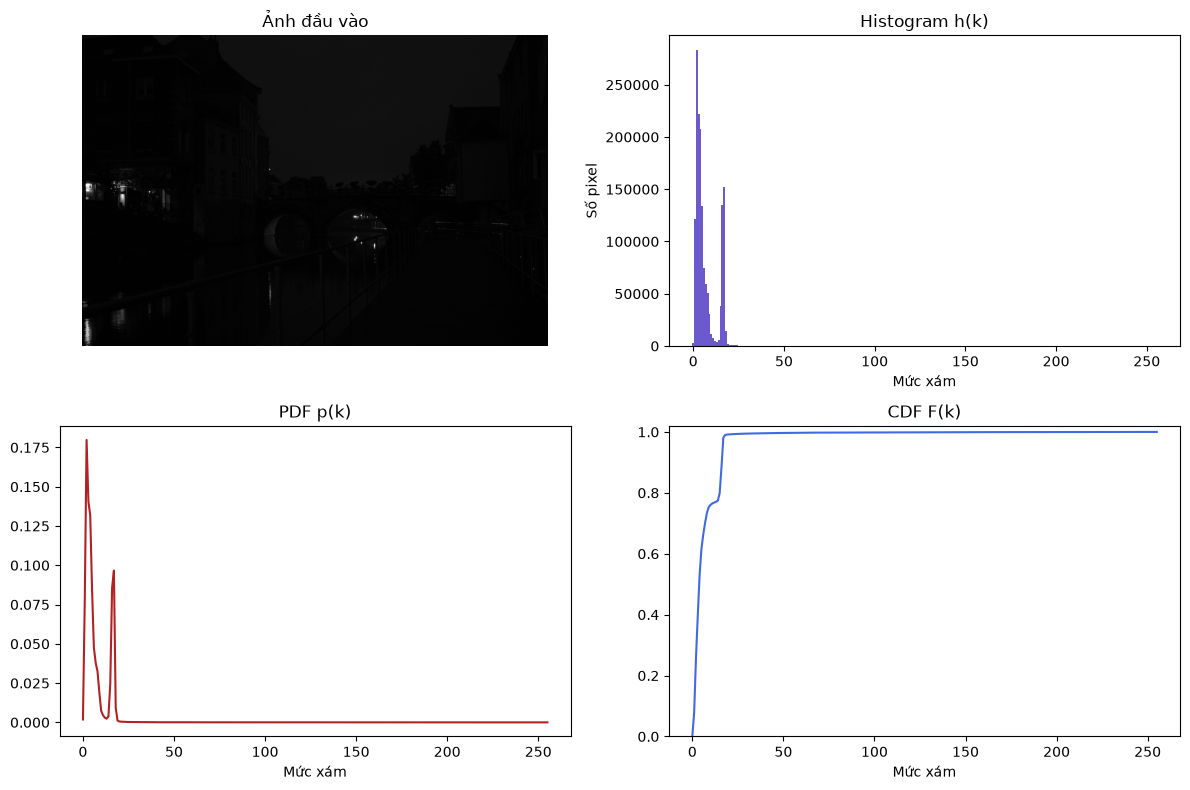

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(low_image, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Ảnh đầu vào")
axes[0, 0].axis("off")
axes[0, 1].bar(np.arange(256), hist, color="slateblue", width=1)
axes[0, 1].set_title("Histogram h(k)")
axes[0, 1].set_xlabel("Mức xám")
axes[0, 1].set_ylabel("Số pixel")
axes[1, 0].plot(np.arange(256), pdf, color="firebrick")
axes[1, 0].set_title("PDF p(k)")
axes[1, 0].set_xlabel("Mức xám")
axes[1, 1].plot(np.arange(256), cdf, color="royalblue")
axes[1, 1].set_title("CDF F(k)")
axes[1, 1].set_ylim(0, 1.02)
axes[1, 1].set_xlabel("Mức xám")
plt.tight_layout(); plt.show()

**Nhận xét:** Ở ảnh thiếu sáng, phần lớn tần suất tập trung về các mức xám thấp; do đó CDF tăng chủ yếu trong miền này.

## 2. Function 01 — Histogram Equalization

### 2.1. Cơ sở lý thuyết

Histogram Equalization ánh xạ mức xám $r$ sang $s$ dựa trên CDF toàn ảnh. Với ảnh 8-bit và CDF chuẩn hóa:

$$
s(r)=\operatorname{round}\!\left(255\,\frac{F(r)-F_{\min}}{1-F_{\min}}\right),
$$

trong đó $F_{\min}$ là CDF ứng với mức xám đầu tiên có tần suất khác 0. Giá trị ánh xạ được giới hạn về $[0,255]$. Trường hợp ảnh chỉ có một mức xám cần xử lý riêng (trong dự án, LUT đơn vị).

**Quy trình xây dựng:** histogram → PDF → CDF → LUT → áp LUT lên ảnh. **Đối chứng:** `cv2.equalizeHist()`.



In [10]:
# Thuật toán từ src/equalization.py:
manual_eq, hist_eq, pdf_eq, cdf_eq, lut_eq = manual_equalization(low_image)
cv_eq = opencv_equalization(low_image)

print("Kích thước kết quả:", manual_eq.shape, cv_eq.shape)
print("Kiểu dữ liệu:", manual_eq.dtype, cv_eq.dtype)
print("LUT có", len(lut_eq), "phần tử")
assert manual_eq.shape == low_image.shape == cv_eq.shape
assert manual_eq.dtype == np.uint8 and cv_eq.dtype == np.uint8

Kích thước kết quả: (1024, 1538) (1024, 1538)
Kiểu dữ liệu: uint8 uint8
LUT có 256 phần tử


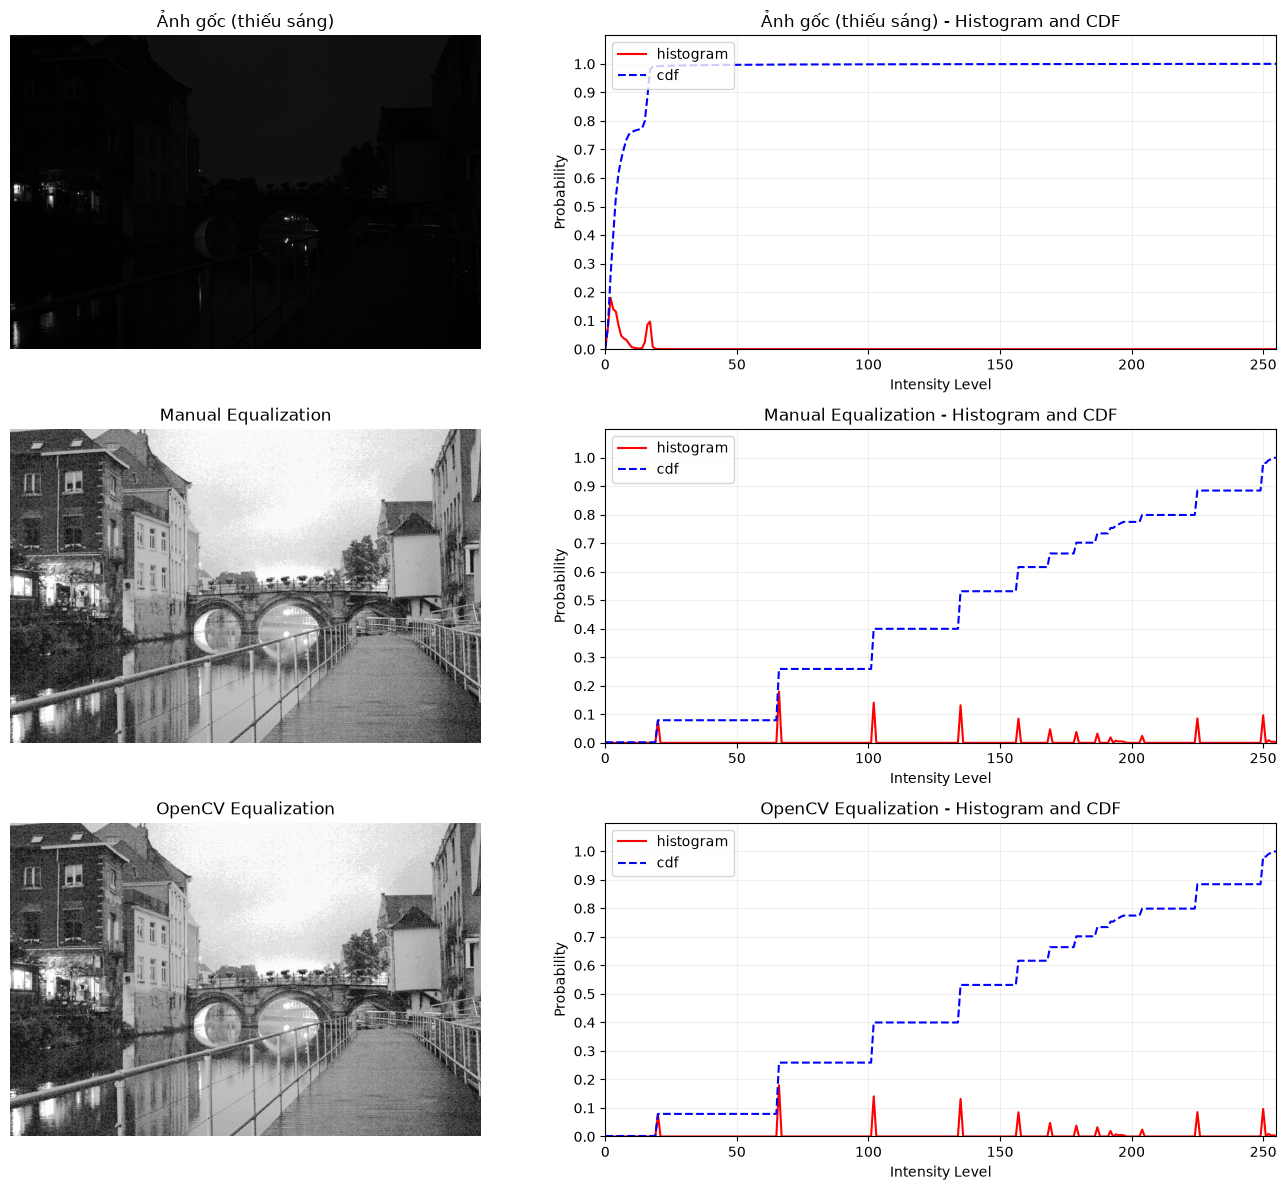

In [11]:
# Sử dụng module visualization.py 
fig = display_results(
    low_image, manual_eq, cv_eq, show=False,
    titles=["Ảnh gốc (thiếu sáng)", "Manual Equalization", "OpenCV Equalization"]
)
display(fig)
plt.close(fig)

In [12]:
# Khảo sát LUT: mỗi mức xám đầu vào được ánh xạ đến giá trị mới.

display(pd.DataFrame({"Mức xám đầu vào": np.arange(256), "Giá trị LUT": lut_eq}).iloc[::16].reset_index(drop=True))

,Mức xám đầu vào,Giá trị LUT
0,0,0
1,16,225
2,32,254
3,48,254
4,64,254
5,80,254
6,96,255
7,112,255
8,128,255
9,144,255


### 2.2. Đánh giá Manual so với OpenCV


In [13]:
#Thuật toán lấy từ src/metrics.py để xem các chỉ số đo lường
def metric_table(image_a, image_b):
    values = calculate_metrics(image_a, image_b)
    values.update(calculate_exact_match(image_a, image_b))
    return pd.DataFrame({"Chỉ số": list(values), "Giá trị": list(values.values())})

display(metric_table(manual_eq, cv_eq))
print("Kiểm tra số pixel đầu ra khác nhau:", int(np.count_nonzero(manual_eq != cv_eq)))

,Chỉ số,Giá trị
0,MAE,0.0
1,MSE,0.0
2,RMSE,0.0
3,PSNR,inf
4,SSIM,1.0
5,NCC,1.0
6,Exact Match (%),100.0
7,Max Absolute Error,0.0


Kiểm tra số pixel đầu ra khác nhau: 0


## 3. Function 02 — Adaptive Histogram Equalization

### 3.1. Cơ sở lý thuyết

**Manual AHE:** với mỗi pixel $(x,y)$, xét cửa sổ lân cận kích thước $w\times w$, tính histogram/CDF cục bộ rồi ánh xạ pixel trung tâm theo CDF của cửa sổ:

$$
s(x,y)=\operatorname{round}\!\left(255\,\frac{F_{\text{local}}(r(x,y))-F_{\min,\text{local}}}{1-F_{\min,\text{local}}}\right).
$$


**CLAHE (đối chứng):** chia ảnh thành các vùng (tiles), cắt/giới hạn histogram (`clipLimit`), phân phối phần dư rồi nội suy giữa các vùng. `tileGridSize=(8,8)` là **số lượng ô theo ngang/dọc**, không phải kích thước pixel mỗi ô.



### 3.2. Demo một cấu hình của hai thuật toán Manual AHE vs CLAHE(openCV)

In [14]:
ahe_input = low_image.copy()
AHE_WINDOW = 15
CLAHE_CLIP = 2.0
CLAHE_GRID = (8, 8)

t0 = time.perf_counter()
ahe_output = manual_ahe(ahe_input, window_size=AHE_WINDOW)
ahe_time = time.perf_counter() - t0

t0 = time.perf_counter()
clahe_output = opencv_clahe(ahe_input, clip_limit=CLAHE_CLIP, tile_grid_size=CLAHE_GRID)
clahe_time = time.perf_counter() - t0
print(f"Kích thước ảnh thử: {ahe_input.shape}")
print(f"Manual AHE ({AHE_WINDOW}×{AHE_WINDOW}): {ahe_time:.3f} giây")
print(f"OpenCV CLAHE ({CLAHE_GRID}, clip={CLAHE_CLIP}): {clahe_time:.3f} giây")

Kích thước ảnh thử: (1024, 1538)
Manual AHE (15×15): 34.109 giây
OpenCV CLAHE ((8, 8), clip=2.0): 0.352 giây


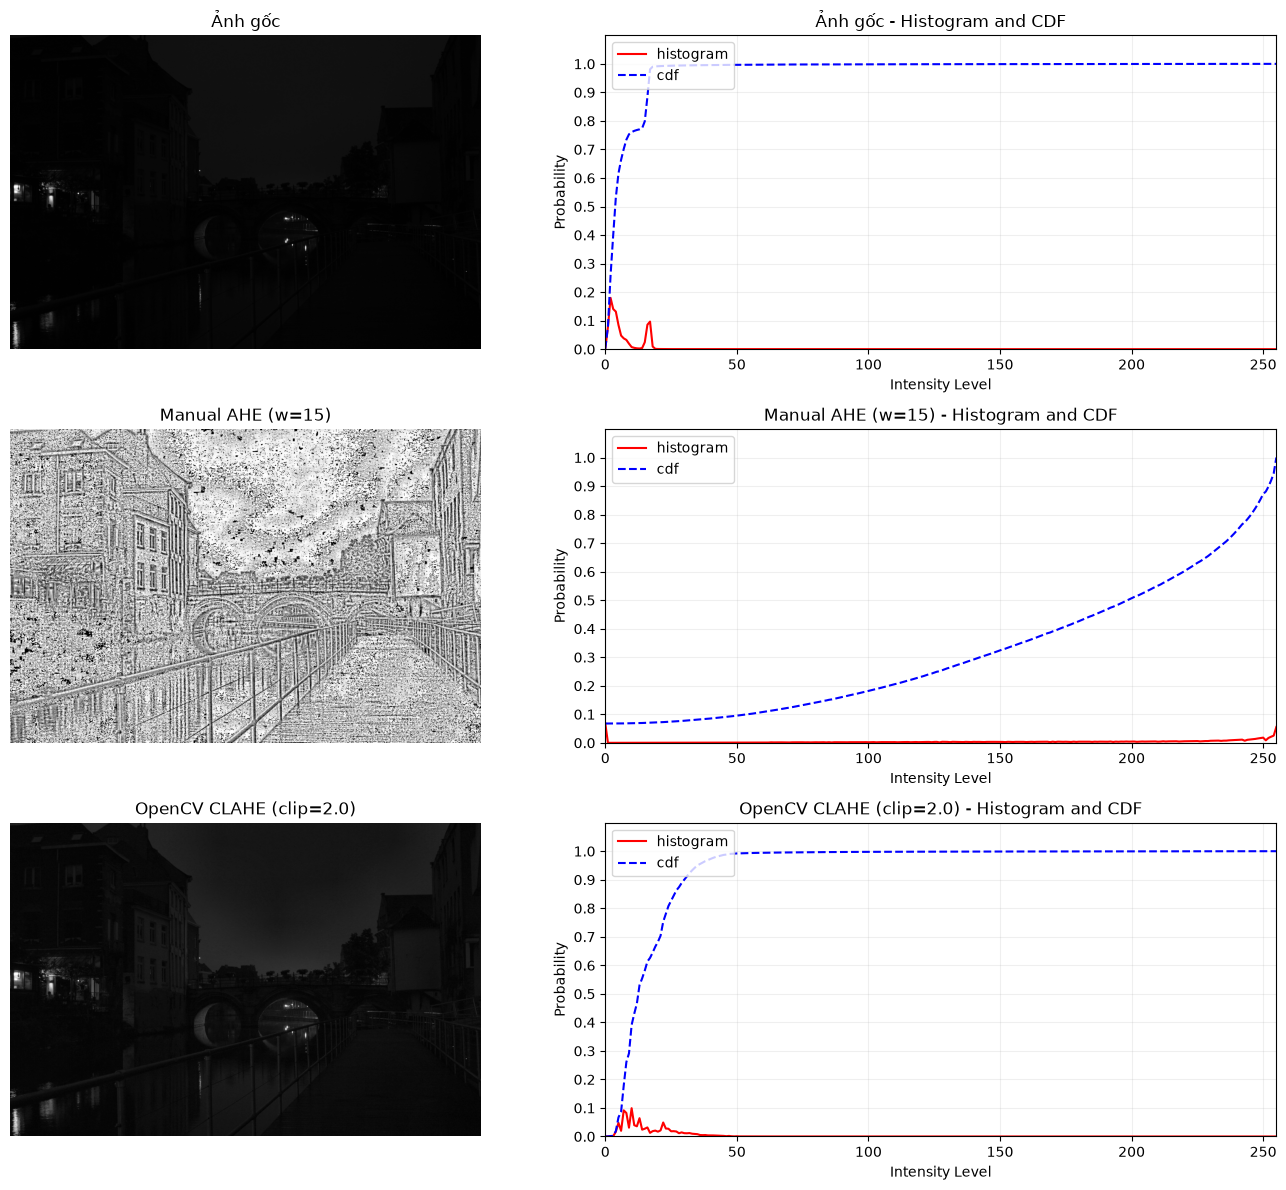

In [15]:
fig = display_results(
    ahe_input, ahe_output, clahe_output, show=False,
    titles=["Ảnh gốc", f"Manual AHE (w={AHE_WINDOW})", f"OpenCV CLAHE (clip={CLAHE_CLIP})"]
)
display(fig); plt.close(fig)

In [16]:
comparison_ahe = pd.DataFrame([
    {"Phương pháp": "Original vs Manual AHE", **calculate_metrics(ahe_input, ahe_output)},
    {"Phương pháp": "Original vs OpenCV CLAHE", **calculate_metrics(ahe_input, clahe_output)}
])
display(comparison_ahe.round(6))

,Phương pháp,MAE,MSE,RMSE,PSNR,SSIM,NCC
0,Original vs Manual AHE,168.719100,33881.961197,184.070533,2.831118,0.008513,0.193299
1,Original vs OpenCV CLAHE,9.517163,120.223312,10.964639,27.330917,0.623214,0.919832


### 3.3. Thí nghiệm A — thay đổi Window Size của Manual AHE

Khảo sát các cửa sổ **9×9, 15×15, 31×31** trên cùng ảnh. Quan sát độ tương phản cục bộ, chi tiết ảnh và khả năng khuếch đại nhiễu.

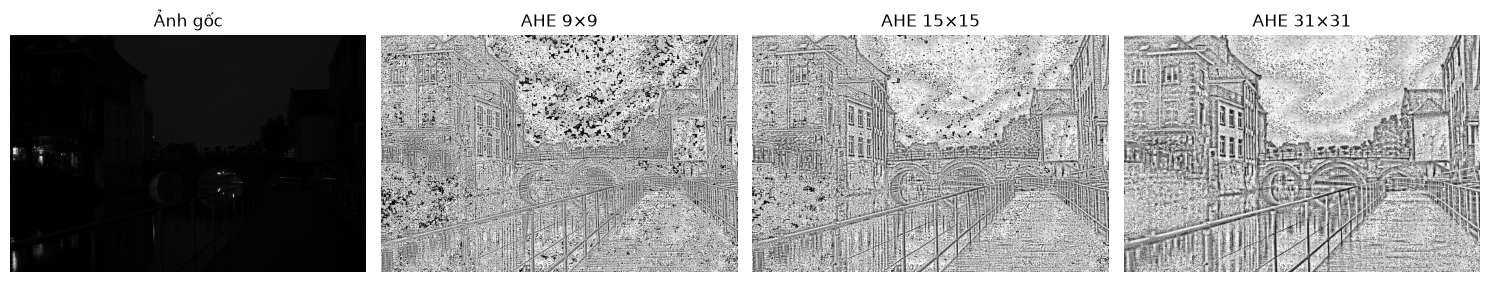

,Window Size,Thời gian (s),Std đầu ra,Min,Max
0,9,34.4180,87.7900,0,255
1,15,37.7832,76.6732,0,255
2,31,38.8439,69.8764,0,255


In [17]:
windows = [9, 15, 31]
ahe_outputs = []
ahe_rows = []
for window in windows:
    start = time.perf_counter()
    result = manual_ahe(ahe_input, window_size=window)
    seconds = time.perf_counter() - start
    ahe_outputs.append(result)
    ahe_rows.append({"Window Size": window, "Thời gian (s)": seconds,
                     "Std đầu ra": float(result.std()), "Min": int(result.min()), "Max": int(result.max())})

fig, axes = plt.subplots(1, len(windows) + 1, figsize=(15, 3.7))
for ax, img, name in zip(axes, [ahe_input] + ahe_outputs,
                         ["Ảnh gốc"] + [f"AHE {w}×{w}" for w in windows]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()
display(pd.DataFrame(ahe_rows).round(4))

### 3.4. Thí nghiệm B — thay đổi Clip Limit của OpenCV CLAHE

Giữ `tileGridSize=(8,8)`; lần lượt thay `clipLimit` bằng 1.0, 2.0, 5.0. Quan sát mức tăng tương phản và thay đổi chi tiết/noise.

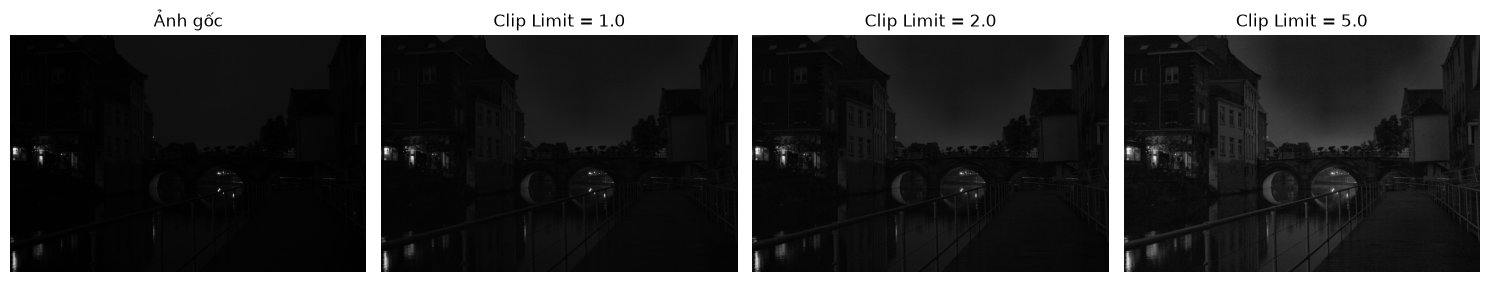

,Clip Limit,Std đầu ra,Min,Max
0,1.0,10.9832,1,255
1,2.0,12.4967,1,255
2,5.0,16.7421,1,255


In [18]:
clip_limits = [1.0, 2.0, 5.0]
clahe_clip_outputs = []
clip_rows = []
for clip in clip_limits:
    result = opencv_clahe(ahe_input, clip_limit=clip, tile_grid_size=(8, 8))
    clahe_clip_outputs.append(result)
    clip_rows.append({"Clip Limit": clip, "Std đầu ra": float(result.std()),
                      "Min": int(result.min()), "Max": int(result.max())})

fig, axes = plt.subplots(1, len(clip_limits) + 1, figsize=(15, 3.6))
for ax, im, title in zip(axes, [ahe_input] + clahe_clip_outputs,
                          ["Ảnh gốc"] + [f"Clip Limit = {v}" for v in clip_limits]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
display(pd.DataFrame(clip_rows).round(4))

### 3.5. Thí nghiệm C — thay đổi Tile Grid Size của OpenCV CLAHE

Giữ `clipLimit=2.0`; thay số lượng ô `(4,4)`, `(8,8)`, `(16,16)`. Một ảnh sẽ được chia theo các mật độ ô khác nhau: số ô càng nhiều thì mỗi ô thường càng nhỏ.

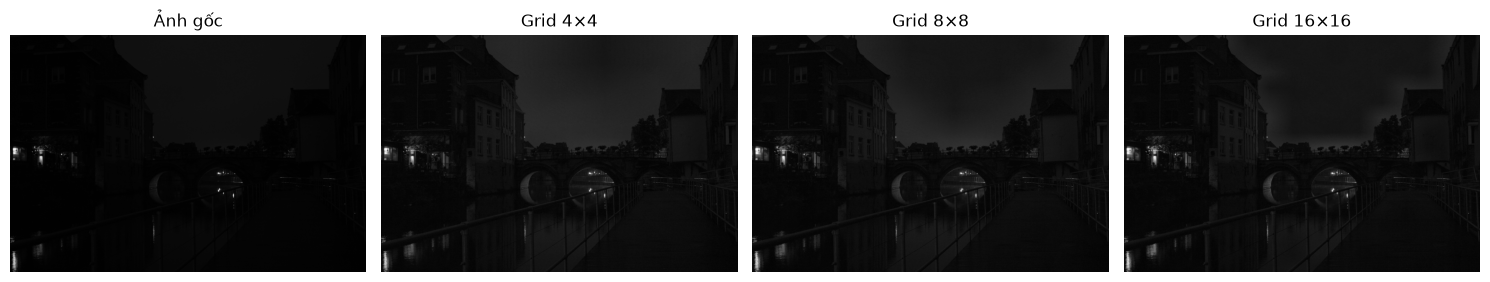

,Tile Grid Size,Std đầu ra,Min,Max
0,"(4, 4)",13.5607,1,255
1,"(8, 8)",12.4967,1,255
2,"(16, 16)",11.9215,1,255


In [19]:
grids = [(4, 4), (8, 8), (16, 16)]
grid_outputs = []
grid_rows = []
for grid in grids:
    result = opencv_clahe(ahe_input, clip_limit=2.0, tile_grid_size=grid)
    grid_outputs.append(result)
    grid_rows.append({"Tile Grid Size": str(grid), "Std đầu ra": float(result.std()),
                      "Min": int(result.min()), "Max": int(result.max())})

fig, axes = plt.subplots(1, len(grids) + 1, figsize=(15, 3.6))
for ax, im, title in zip(axes, [ahe_input] + grid_outputs,
                         ["Ảnh gốc"] + [f"Grid {v[0]}×{v[1]}" for v in grids]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
display(pd.DataFrame(grid_rows).round(4))

## 4. Function 03 — Histogram Matching

### 4.1. Cơ sở lý thuyết

**Mục tiêu:** điều chỉnh phân bố mức xám của ảnh **Source** để tiến gần phân bố mức xám của ảnh **Target**, không yêu cầu hai ảnh giống nhau về nội dung/kích thước.

Tính CDF $F_S$ cho Source và $F_T$ cho Target. Với mức xám xuất hiện trong Source là $r$, tính phân vị $q=F_S(r)$, sau đó ánh xạ theo CDF Target:

$$
s(r)\approx F_T^{-1}(q),\qquad q=F_S(r).
$$


**Quy trình:** tính histogram của source và target → CDF → ánh xạ quantile → LUT → áp dụng ảnh nguồn. **Đối chứng:** `skimage.exposure.match_histograms()`.


In [34]:
# Chạy Manual và scikit-image
IMAGE_PATHS_2 = {
    "source": Path("images/high-exposure.jpg"),
    "target": Path("images/lena.jpg"),
}

source_image = load_gray_or_fallback(IMAGE_PATHS_2["source"], base)
target_image = load_gray_or_fallback(IMAGE_PATHS_2["target"], demo_target)

matched_float, matching_lut = manual_histogram_matching(source_image, target_image, return_lut=True)
reference_float = skimage_histogram_matching(source_image, target_image)
matched_image = convert_matching_to_8bit(matched_float)
reference_image = convert_matching_to_8bit(reference_float)

assert matched_image.shape == source_image.shape
assert reference_image.shape == source_image.shape
print("Source:", source_image.shape, "Target:", target_image.shape)

Đã tải images\high-exposure.jpg: (1024, 1538), uint8
Đã tải images\lena.jpg: (512, 512), uint8
Source: (1024, 1538) Target: (512, 512)


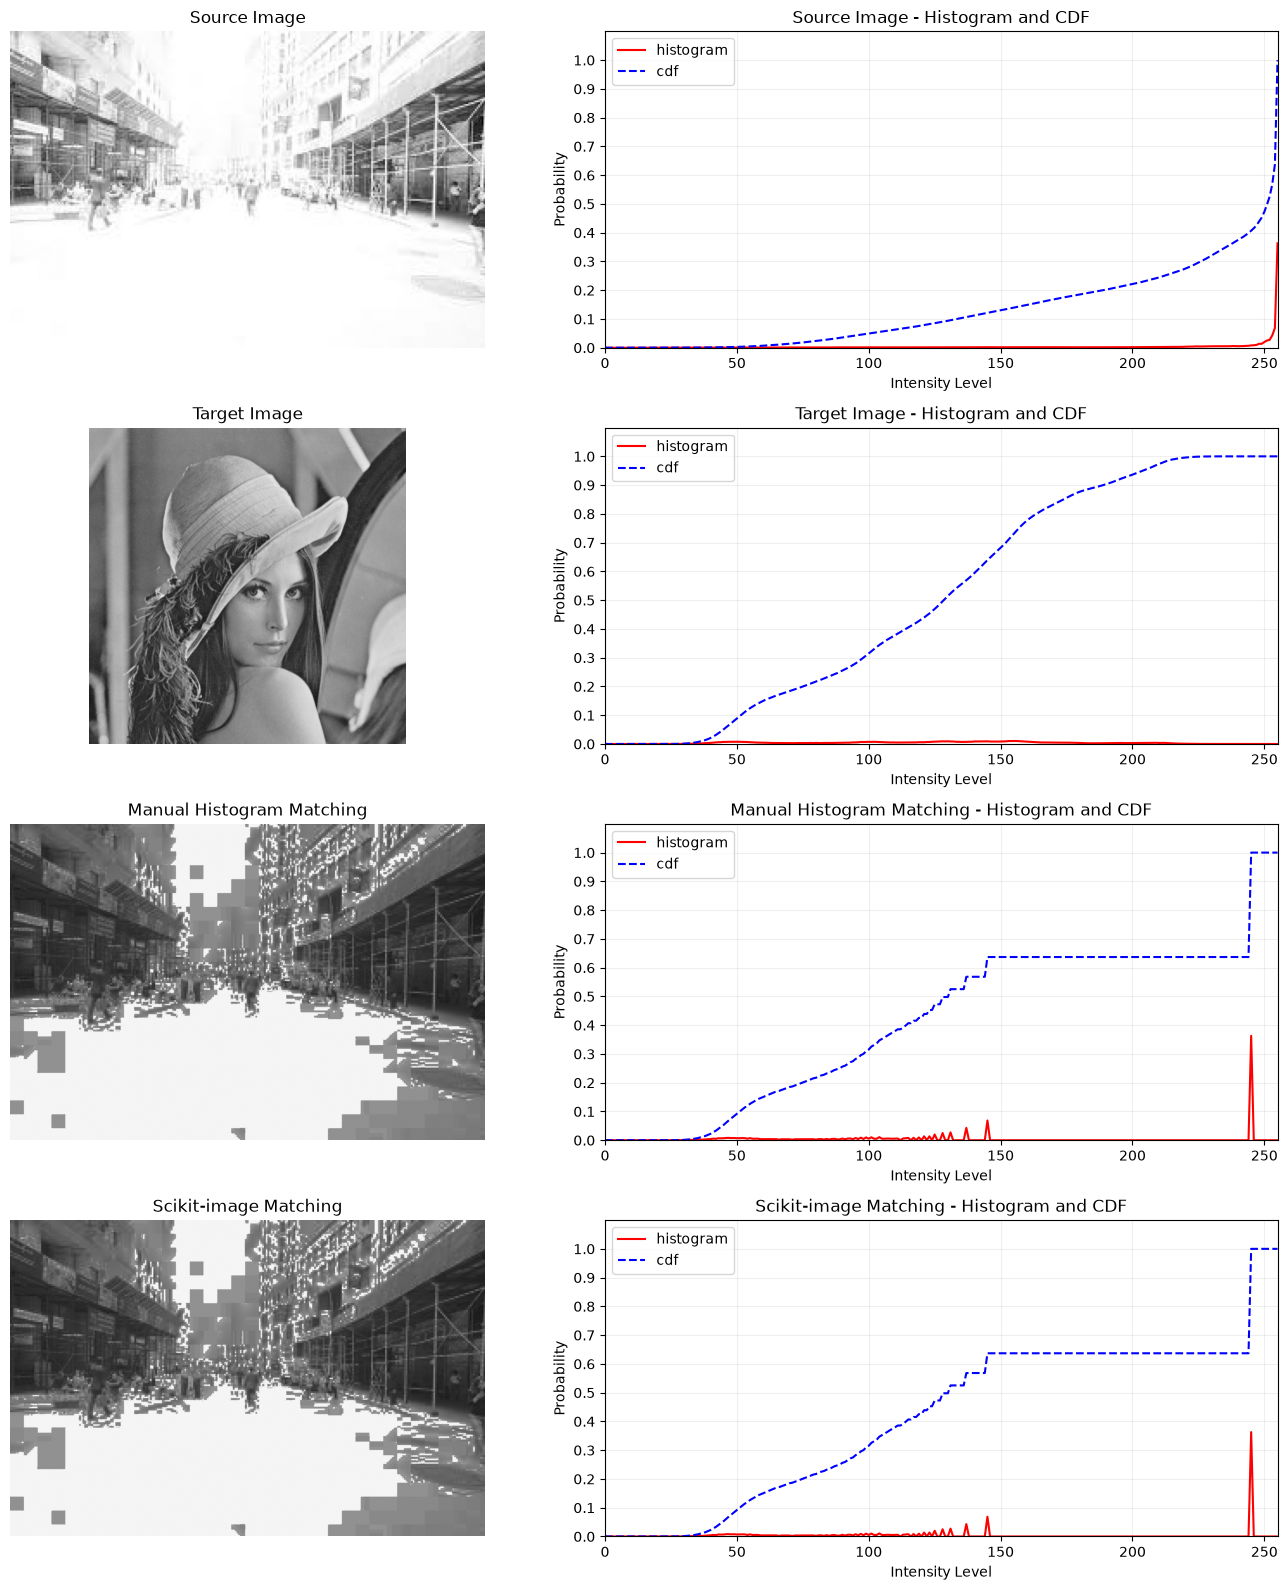

In [35]:
fig = display_results(
    source_image, target_image, matched_image,
    additional_image=reference_image, show=False,
    titles=["Source Image", "Target Image", "Manual Histogram Matching", "Scikit-image Matching"]
)
display(fig); plt.close(fig)

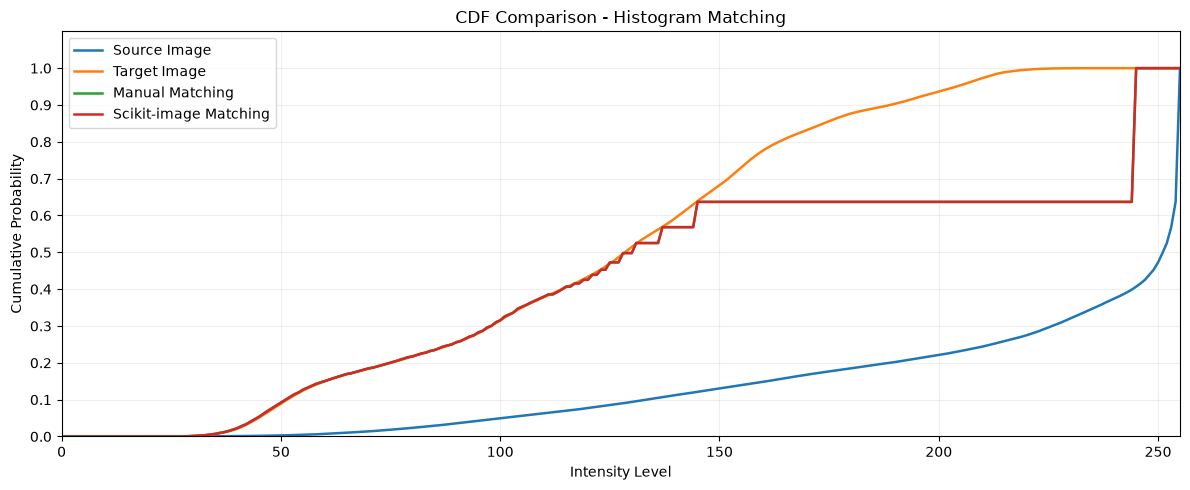

In [36]:
# Các đường CDF: Source / Target / Manual / Thư viện.
fig = display_cdf_comparison(source_image, target_image, matched_image, reference_image)
display(fig); plt.close(fig)

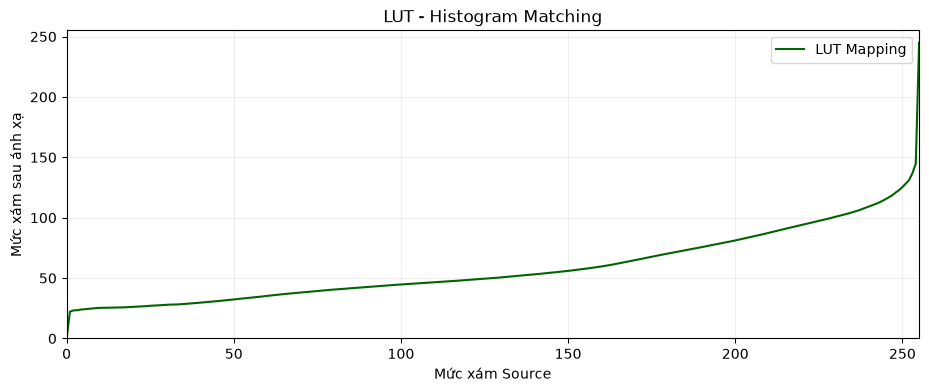

,Source Gray Level,Mapped Value
0,0,0.000000
1,16,25.742176
2,32,28.104787
3,48,31.754252
4,64,36.453992
5,80,40.534303
6,96,43.988462
7,112,46.947808
8,128,50.129409
9,144,54.218433


In [40]:
# LUT là 256 giá trị. Chỉ các mức xám xuất hiện trong Source mới có tác dụng lên ảnh.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(np.arange(256), matching_lut, label="LUT Mapping", color="darkgreen")
ax.set(xlim=(0, 255), ylim=(0, 255), title="LUT - Histogram Matching",
       xlabel="Mức xám Source", ylabel="Mức xám sau ánh xạ")
ax.legend(); ax.grid(alpha=0.2)
plt.show()
display(pd.DataFrame({"Source Gray Level": np.arange(256), "Mapped Value": matching_lut}).iloc[::16].reset_index(drop=True))

### 4.2. Đánh giá thuật toán và chất lượng Matching

Có **hai bài toán đánh giá khác nhau**:

1. **Độ khớp triển khai** (Manual vs scikit-image): MAE, MSE, RMSE, PSNR, SSIM, NCC, Exact Match (%), Max Absolute Error, và sai khác trước lượng tử hóa.
2. **Độ gần phân bố so với Target**: Histogram L1 và Wasserstein-1 của Source/Manual/scikit-image so với Target. Giá trị nhỏ hơn cho biết **phân bố mức xám** gần hơn, không có nghĩa ảnh có nội dung giống nhau.

Với histogram chuẩn hóa $p$ và $q$:

$$L_1(p,q)=\sum_{k=0}^{255}|p(k)-q(k)|$$

$$W_1(p,q)=\sum_{k=0}^{254}|F_p(k)-F_q(k)|$$

$W_1$ ở đây là khoảng cách Wasserstein-1 trên trục mức xám cách đều 1 đơn vị.

In [43]:
# So sánh hai cách triển khai ở cùng không gian ảnh (kích thước Source).
display(metric_table(matched_image, reference_image))

# So sánh phân bố: không yêu cầu kích thước Source và Target trùng nhau.
distance_rows = []
for name, img in [
    ("Source", source_image),
    ("Manual Matching", matched_image),
    ("Scikit-image Matching", reference_image)
]:
    distance_rows.append({"Ảnh": name, **calculate_histogram_distance(img, target_image)})
display(pd.DataFrame(distance_rows).round(6))

,Chỉ số,Giá trị
0,MAE,0.0
1,MSE,0.0
2,RMSE,0.0
3,PSNR,inf
4,SSIM,1.0
5,NCC,1.0
6,Exact Match (%),100.0
7,Max Absolute Error,0.0


,Ảnh,Histogram L1,Wasserstein-1
0,Source,1.462401,98.636217
1,Manual Matching,1.131442,26.413758
2,Scikit-image Matching,1.131442,26.413758
